# Pre-entrega 3 — Modelo supervisado

**Proyecto:** Análisis y predicción del rendimiento productivo en pozos de petróleo y gas de Argentina
**Programa:** EnergIA Digital — Data Science (Fundación YPF)
**Integrantes:** Mariapia Ortiz y Antonella Fontanetto
**Comisión:** 2

## Objetivo

¿Se puede anticipar cuánto petróleo va a producir un pozo en un mes conociendo sólo **qué pozo es y dónde
está**: cuenca, provincia, formación, tipo de recurso, sistema de extracción, profundidad, operadora y días
que trabajó?

Planteamos la pregunta de dos formas, con el mismo punto de partida (el dataset procesado del notebook 01):

1. **Regresión:** predecir la producción mensual de petróleo en m³ (`prod_pet`).
2. **Clasificación:** predecir si el pozo-mes cae en el rango de productividad **Baja, Media o Alta**.

Para cada problema comparamos varios algoritmos con validación cruzada, elegimos uno, optimizamos sus
hiperparámetros con **Optuna** para controlar el sobreajuste y lo evaluamos **una sola vez** en test.

In [1]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, f1_score,
                             mean_absolute_error, r2_score, roc_auc_score, root_mean_squared_error)
from sklearn.model_selection import GroupKFold, cross_val_score, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid")
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 1. Datos y variables predictoras

Partimos del dataset que dejó el notebook 01: pozos petrolíferos en extracción efectiva durante 2025, ya limpios.

In [2]:
pet = pd.read_csv("../data/processed/pozos_petroleros_2025.csv.gz")
print(f"{len(pet):,} filas pozo-mes | {pet['idpozo'].nunique():,} pozos")

263,937 filas pozo-mes | 24,388 pozos


**Qué entra al modelo y qué no.** La pregunta es qué se puede anticipar del pozo *antes* de medir su producción.
Por eso usamos sólo características del pozo y del mes:

| Tipo | Variables |
|---|---|
| Numéricas | `profundidad`, `tef` (días efectivos), `mes` |
| Categóricas | `cuenca`, `provincia`, `tipo_de_recurso`, `sub_tipo_recurso`, `tipoextraccion`, `formprod`, `empresa` |

Dejamos afuera, a propósito, `prod_gas`, `prod_agua`, `caudal_diario`, `corte_agua` y `rgp`: se miden **en el mismo
momento** que el petróleo (y `caudal_diario` es el petróleo dividido por los días). Usarlas sería **fuga de
información**: el modelo daría muy bien en el notebook y no serviría para anticipar nada.

In [3]:
numericas = ["profundidad", "tef", "mes"]
categoricas = ["cuenca", "provincia", "tipo_de_recurso", "sub_tipo_recurso",
               "tipoextraccion", "formprod", "empresa"]

X = pet[numericas + categoricas]
grupos = pet["idpozo"]
X[categoricas].nunique()

cuenca               5
provincia           11
tipo_de_recurso      3
sub_tipo_recurso     3
tipoextraccion      11
formprod            63
empresa             57
dtype: int64

## 2. Separación en entrenamiento y test, por pozo

Igual que en el notebook 01 (misma semilla, mismo test): cada pozo aparece hasta 12 veces, así que separamos
**por pozo** con `GroupKFold` (5 partes, la primera es el test). Si un pozo quedara de los dos lados, el modelo lo "reconocería" en test.

In [4]:
separador = GroupKFold(n_splits=5, shuffle=True, random_state=42)
idx_train, idx_test = next(separador.split(X, groups=grupos))

X_train, X_test = X.iloc[idx_train], X.iloc[idx_test]
grupos_train = grupos.iloc[idx_train]
prod_train, prod_test = pet["prod_pet"].iloc[idx_train], pet["prod_pet"].iloc[idx_test]

print(f"Entrenamiento: {len(X_train):,} filas, {grupos_train.nunique():,} pozos")
print(f"Test: {len(X_test):,} filas, {grupos.iloc[idx_test].nunique():,} pozos")
print("Pozos en ambos conjuntos:", len(set(grupos_train) & set(grupos.iloc[idx_test])))

Entrenamiento: 211,183 filas, 19,510 pozos
Test: 52,754 filas, 4,878 pozos
Pozos en ambos conjuntos: 0


**Muestra para comparar y optimizar.** La validación cruzada entrena cada modelo 5 veces, y Optuna repite eso
decenas de veces. Con 200.000 filas eso tarda horas en una computadora común o en Colab. Para comparar y
optimizar usamos una muestra de **6.000 pozos de entrenamiento** (todos sus meses). El modelo final se entrena
con **todo** el entrenamiento.

In [5]:
rng = np.random.default_rng(42)
pozos_muestra = rng.choice(grupos_train.unique(), size=6000, replace=False)
en_muestra = grupos_train.isin(pozos_muestra).to_numpy()

X_muestra, grupos_muestra = X_train[en_muestra], grupos_train[en_muestra]
print(f"Muestra: {len(X_muestra):,} filas de {grupos_muestra.nunique():,} pozos")

Muestra: 64,772 filas de 6,000 pozos


## 3. Preprocesamiento dentro de un pipeline

Todo el preprocesamiento va **dentro del pipeline** (clase 16): en cada fold de la validación cruzada se vuelve
a ajustar sólo con los datos de entrenamiento de ese fold, sin espiar el de validación.

- **Numéricas:** la profundidad faltante se imputa con la mediana. El escalado se agrega sólo para los modelos
  lineales; los árboles no lo necesitan.
- **Categóricas:** `OneHotEncoder`. Con `min_frequency=500` las categorías con menos de 500 filas se juntan en
  una sola columna de "poco frecuentes" (lo mismo que hicimos a mano con `formprod` en el notebook 01), y
  `handle_unknown` manda ahí a las categorías que aparezcan en test sin haberse visto en entrenamiento.

In [6]:
def preprocesador(escalar):
    pasos_numericos = [("imputar", SimpleImputer(strategy="median"))]
    if escalar:
        pasos_numericos.append(("escalar", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(pasos_numericos), numericas),
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=500,
                              sparse_output=False), categoricas),
    ])


def modelo(algoritmo, escalar=False):
    return Pipeline([("prep", preprocesador(escalar)), ("modelo", algoritmo)])


cv = GroupKFold(n_splits=5)

# Parte A — Regresión: ¿cuántos m³ va a producir?

## 4. Variable objetivo

En el notebook 01 vimos que `prod_pet` tiene asimetría extrema (skew 9). Modelamos `log1p(prod_pet)`: así un
error de 50 m³ pesa mucho en un pozo de 10 m³ y poco en uno de 5.000, que es lo que queremos. Para informar los
resultados volvemos a m³ con `expm1`.

In [7]:
y_train_reg = np.log1p(prod_train)
y_test_reg = np.log1p(prod_test)
y_muestra_reg = y_train_reg[en_muestra]

## 5. Comparación de algoritmos con validación cruzada

Comparamos cuatro modelos. El `DummyRegressor` predice siempre la media: es la vara mínima que cualquier
modelo tiene que superar. Pedimos también el puntaje en entrenamiento (`return_train_score`) para ver el
**sobreajuste**: si entrena muy bien y valida mal, memorizó.

In [8]:
candidatos_reg = {
    "Dummy (media)": modelo(DummyRegressor()),
    "Regresión lineal": modelo(LinearRegression(), escalar=True),
    "Árbol de decisión": modelo(DecisionTreeRegressor(random_state=42)),
    "Random Forest": modelo(RandomForestRegressor(n_estimators=50, random_state=42, n_jobs=-1)),
}


def comparar(candidatos, y, metricas, principal):
    filas = {}
    for nombre, pipe in candidatos.items():
        inicio = time.time()
        res = cross_validate(pipe, X_muestra, y, groups=grupos_muestra, cv=cv,
                             scoring=metricas, return_train_score=True)
        filas[nombre] = {
            f"{principal} entrenamiento": res[f"train_{principal}"].mean(),
            f"{principal} validación": res[f"test_{principal}"].mean(),
            f"{principal} desvío": res[f"test_{principal}"].std(),
            **{f"{m} validación": res[f"test_{m}"].mean() for m in metricas if m != principal},
            "segundos": time.time() - inicio,
        }
    return pd.DataFrame(filas).T


comparacion_reg = comparar(candidatos_reg, y_muestra_reg,
                           ["r2", "neg_mean_absolute_error"], principal="r2")
comparacion_reg

,r2 entrenamiento,r2 validación,r2 desvío,neg_mean_absolute_error validación,segundos
Dummy (media),0.000,-0.001,0.000,-1.218,3.775
Regresión lineal,0.615,0.603,0.011,-0.775,7.210
Árbol de decisión,0.985,0.397,0.049,-0.928,7.025
Random Forest,0.971,0.558,0.033,-0.798,132.703


**Lectura** (los valores negativos de MAE son una convención de scikit-learn: "más alto es mejor"):

- **El árbol de decisión sin límites es el ejemplo de manual del sobreajuste**: R² cercano a 1 en
  entrenamiento y mucho más bajo en validación. Aprendió de memoria los pozos que vio.
- El **Random Forest** por defecto también sobreajusta (gran distancia entre entrenamiento y validación),
  aunque menos, porque promedia muchos árboles.
- La **regresión lineal** valida incluso mejor que el Random Forest por defecto, y sin sobreajuste: entrena y
  valida casi igual.

Igual elegimos optimizar el **Random Forest**: su problema (el sobreajuste) se controla con hiperparámetros,
así que tiene margen de mejora. La regresión lineal no tiene hiperparámetros que mover. Si el Random Forest
optimizado no superara a la regresión lineal, nos quedaríamos con la lineal, que es más simple.

## 6. Optimización de hiperparámetros con Optuna

Optuna (clase 13) prueba combinaciones de hiperparámetros y aprende de las anteriores para elegir la siguiente.
Los que movemos atacan el sobreajuste:

- `min_samples_leaf`: cuántas filas como mínimo debe tener cada hoja. Más grande = árboles menos detallistas.
- `max_depth`: profundidad máxima de cada árbol.
- `max_features`: qué fracción de variables mira cada corte. Menos = árboles más distintos entre sí.
- `n_estimators`: cantidad de árboles.

Cada prueba se evalúa con validación cruzada por pozo (3 folds para que entre en tiempo) sobre una muestra de
3.000 pozos.

In [9]:
pozos_optuna = rng.choice(pozos_muestra, size=3000, replace=False)
en_optuna = grupos_muestra.isin(pozos_optuna).to_numpy()
X_optuna, grupos_optuna = X_muestra[en_optuna], grupos_muestra[en_optuna]
cv_optuna = GroupKFold(n_splits=3)


def hiperparametros(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 50, 150, step=50),
        "max_depth": trial.suggest_int("max_depth", 5, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 50, log=True),
        "max_features": trial.suggest_categorical("max_features", ["sqrt", 0.3, 0.6, 1.0]),
    }


def objetivo_reg(trial):
    pipe = modelo(RandomForestRegressor(**hiperparametros(trial), random_state=42, n_jobs=-1))
    return cross_val_score(pipe, X_optuna, y_muestra_reg[en_optuna], groups=grupos_optuna,
                           cv=cv_optuna, scoring="r2").mean()


inicio = time.time()
estudio_reg = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
estudio_reg.optimize(objetivo_reg, n_trials=20)
print(f"{time.time() - inicio:.0f} s | mejor R² en validación: {estudio_reg.best_value:.3f}")
estudio_reg.best_params

310 s | mejor R² en validación: 0.663


{'n_estimators': 150,
 'max_depth': 16,
 'min_samples_leaf': 13,
 'max_features': 0.3}

In [10]:
(estudio_reg.trials_dataframe()[["number", "value", "params_n_estimators", "params_max_depth",
                                 "params_min_samples_leaf", "params_max_features"]]
    .sort_values("value", ascending=False).head(8))

,number,value,params_n_estimators,params_max_depth,params_min_samples_leaf,params_max_features
11,11,0.663,150,16,13,0.300
1,1,0.662,150,20,13,0.300
12,12,0.662,150,20,13,0.300
3,3,0.662,50,12,3,0.300
17,17,0.661,150,12,9,0.300
18,18,0.657,100,25,7,0.300
15,15,0.653,100,13,25,0.300
14,14,0.653,100,20,29,0.300


Comparamos el Random Forest optimizado contra el que usa los valores por defecto, con la **misma** validación
cruzada de 5 folds del paso 5, y miramos de nuevo la distancia entre entrenamiento y validación:

In [11]:
rf_reg_optimizado = modelo(RandomForestRegressor(**estudio_reg.best_params, random_state=42, n_jobs=-1))
comparar({"Random Forest por defecto": candidatos_reg["Random Forest"],
          "Random Forest optimizado": rf_reg_optimizado},
         y_muestra_reg, ["r2", "neg_mean_absolute_error"], principal="r2")

,r2 entrenamiento,r2 validación,r2 desvío,neg_mean_absolute_error validación,segundos
Random Forest por defecto,0.971,0.558,0.033,-0.798,224.060
Random Forest optimizado,0.754,0.682,0.012,-0.682,86.328


## 7. Evaluación final en test

Entrenamos el modelo elegido con **todo** el entrenamiento y lo evaluamos en test **una sola vez**. Reportamos
las tres métricas de la clase 15, en la escala del modelo (log) y en m³.

In [12]:
inicio = time.time()
rf_reg_optimizado.fit(X_train, y_train_reg)
print(f"Entrenado en {time.time() - inicio:.0f} s")

pred_log = rf_reg_optimizado.predict(X_test)
pred_m3 = np.expm1(pred_log)

pd.DataFrame({
    "escala log1p": [r2_score(y_test_reg, pred_log), mean_absolute_error(y_test_reg, pred_log),
                     root_mean_squared_error(y_test_reg, pred_log)],
    "m³/mes": [r2_score(prod_test, pred_m3), mean_absolute_error(prod_test, pred_m3),
               root_mean_squared_error(prod_test, pred_m3)],
}, index=["R²", "MAE", "RMSE"])

Entrenado en 101 s


,escala log1p,m³/mes
R²,0.706,0.601
MAE,0.652,89.248
RMSE,0.913,360.635


In [13]:
error_relativo = np.exp(mean_absolute_error(y_test_reg, pred_log))
print(f"MAE en log = {mean_absolute_error(y_test_reg, pred_log):.2f} → la predicción típica se equivoca "
      f"por un factor de {error_relativo:.1f} (para arriba o para abajo)")
print(f"Mediana de prod_pet en test: {prod_test.median():,.0f} m³/mes")

MAE en log = 0.65 → la predicción típica se equivoca por un factor de 1.9 (para arriba o para abajo)
Mediana de prod_pet en test: 42 m³/mes


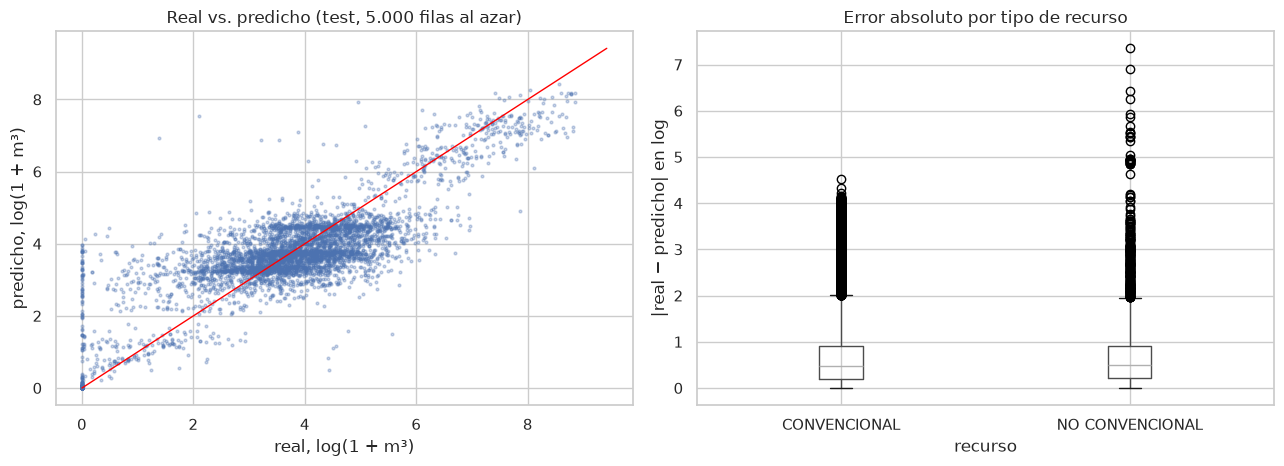

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
muestra_graf = np.random.default_rng(0).choice(len(y_test_reg), 5000, replace=False)
axes[0].scatter(y_test_reg.iloc[muestra_graf], pred_log[muestra_graf], s=4, alpha=0.3)
limites = [0, y_test_reg.max()]
axes[0].plot(limites, limites, color="red", lw=1)
axes[0].set_xlabel("real, log(1 + m³)")
axes[0].set_ylabel("predicho, log(1 + m³)")
axes[0].set_title("Real vs. predicho (test, 5.000 filas al azar)")

recurso_test = pet["tipo_de_recurso"].iloc[idx_test]
pd.DataFrame({"error_abs_log": np.abs(y_test_reg - pred_log), "recurso": recurso_test}) \
    .boxplot(column="error_abs_log", by="recurso", ax=axes[1])
axes[1].set_title("Error absoluto por tipo de recurso")
axes[1].set_ylabel("|real − predicho| en log")
plt.suptitle("")
plt.tight_layout()
plt.show()

Los puntos siguen la diagonal, pero el modelo **comprime los extremos**: a los pozos que menos producen les predice
de más y a los que más producen, de menos. La columna de puntos sobre el 0 real son pozos-mes que declararon días
trabajados pero 0 m³: con las variables disponibles no se pueden distinguir. El error típico es parecido en
convencionales y no convencionales, aunque los no convencionales tienen los errores más grandes.

### ¿Qué variables usa el modelo?

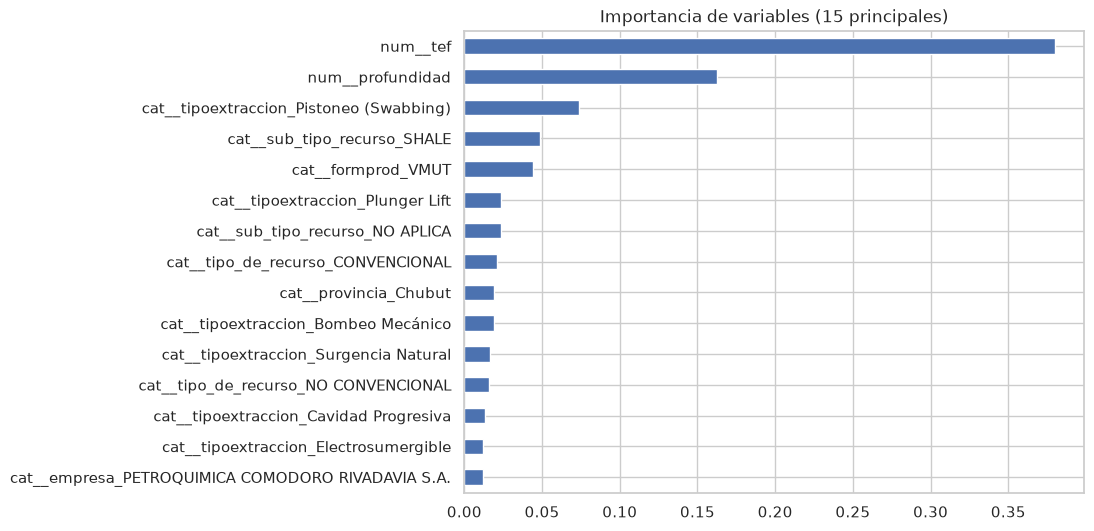

In [15]:
nombres = rf_reg_optimizado.named_steps["prep"].get_feature_names_out()
importancia_reg = pd.Series(rf_reg_optimizado.named_steps["modelo"].feature_importances_, index=nombres)
importancia_reg.sort_values().tail(15).plot.barh(figsize=(8, 6), title="Importancia de variables (15 principales)")
plt.show()

Los **días efectivos** (`tef`) son la variable más usada: un pozo que trabajó 5 días produce menos en el mes que
uno que trabajó 30. Le siguen la **profundidad** (ya en el notebook 01 era la característica más correlacionada
con la producción), el sistema de extracción (el pistoneo es típico de pozos de bajo caudal) y las marcas del no
convencional: subtipo *shale* y formación Vaca Muerta (`VMUT`). La importancia de un Random Forest tiende a
favorecer a las variables numéricas, que admiten muchos cortes; por eso conviene leerla como orden aproximado y
no como medida exacta.

# Parte B — Clasificación: ¿productividad baja, media o alta?

## 8. Variable objetivo

En el notebook 01 creamos `rango_productividad` con terciles de **todo** el dataset. Para modelar, los cortes
se recalculan **sólo con entrenamiento** y se aplican al test, para que el test no influya en cómo se define
la clase.

In [16]:
_, cortes = pd.qcut(prod_train, q=3, retbins=True)
cortes[0], cortes[-1] = -np.inf, np.inf
clases = ["Baja", "Media", "Alta"]

y_train_clf = pd.cut(prod_train, bins=cortes, labels=clases)
y_test_clf = pd.cut(prod_test, bins=cortes, labels=clases)
y_muestra_clf = y_train_clf[en_muestra]

print("Cortes (m³/mes):", cortes[1:-1].round(1))
pd.DataFrame({"entrenamiento %": y_train_clf.value_counts(normalize=True) * 100,
              "test %": y_test_clf.value_counts(normalize=True) * 100}).round(1)

Cortes (m³/mes): [24.8 68.5]


,entrenamiento %,test %
prod_pet,,
Baja,33.300,32.800
Media,33.300,33.400
Alta,33.300,33.800


Las tres clases quedan casi del mismo tamaño en los dos conjuntos: no hay desbalance que corregir. Como métrica
principal usamos **F1 macro** (promedio del F1 de las tres clases), que exige que el modelo acierte las tres y no
sólo la más fácil.

## 9. Comparación de algoritmos con validación cruzada

In [17]:
candidatos_clf = {
    "Dummy (clase más frecuente)": modelo(DummyClassifier()),
    "Regresión logística": modelo(LogisticRegression(max_iter=1000), escalar=True),
    "Árbol de decisión": modelo(DecisionTreeClassifier(random_state=42)),
    "Random Forest": modelo(RandomForestClassifier(n_estimators=50, random_state=42, n_jobs=-1)),
}
comparacion_clf = comparar(candidatos_clf, y_muestra_clf,
                           ["f1_macro", "accuracy", "roc_auc_ovr"], principal="f1_macro")
comparacion_clf

,f1_macro entrenamiento,f1_macro validación,f1_macro desvío,accuracy validación,roc_auc_ovr validación,segundos
Dummy (clase más frecuente),0.168,0.167,0.001,0.336,0.500,6.947
Regresión logística,0.599,0.586,0.008,0.583,0.775,199.920
Árbol de decisión,0.974,0.534,0.009,0.534,0.654,14.606
Random Forest,0.973,0.557,0.011,0.556,0.750,46.837


El patrón se repite: el árbol sin límites memoriza, el Random Forest por defecto también muestra una distancia
grande entre entrenamiento y validación, y el modelo lineal (regresión logística) valida mejor que los dos.
Volvemos a optimizar el **Random Forest** con Optuna, ahora maximizando el F1 macro, con el mismo criterio: si
no supera a la regresión logística, nos quedamos con la logística.

## 10. Optimización con Optuna

In [18]:
def objetivo_clf(trial):
    pipe = modelo(RandomForestClassifier(**hiperparametros(trial), random_state=42, n_jobs=-1))
    return cross_val_score(pipe, X_optuna, y_muestra_clf[en_optuna], groups=grupos_optuna,
                           cv=cv_optuna, scoring="f1_macro").mean()


inicio = time.time()
estudio_clf = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
estudio_clf.optimize(objetivo_clf, n_trials=20)
print(f"{time.time() - inicio:.0f} s | mejor F1 macro en validación: {estudio_clf.best_value:.3f}")
estudio_clf.best_params

164 s | mejor F1 macro en validación: 0.589


{'n_estimators': 50,
 'max_depth': 17,
 'min_samples_leaf': 18,
 'max_features': 'sqrt'}

In [19]:
rf_clf_optimizado = modelo(RandomForestClassifier(**estudio_clf.best_params, random_state=42, n_jobs=-1))
comparar({"Random Forest por defecto": candidatos_clf["Random Forest"],
          "Random Forest optimizado": rf_clf_optimizado},
         y_muestra_clf, ["f1_macro", "accuracy", "roc_auc_ovr"], principal="f1_macro")

,f1_macro entrenamiento,f1_macro validación,f1_macro desvío,accuracy validación,roc_auc_ovr validación,segundos
Random Forest por defecto,0.973,0.557,0.011,0.556,0.750,32.285
Random Forest optimizado,0.662,0.602,0.012,0.601,0.789,18.065


## 11. Evaluación final en test

In [20]:
rf_clf_optimizado.fit(X_train, y_train_clf)
pred_clf = rf_clf_optimizado.predict(X_test)
proba_clf = rf_clf_optimizado.predict_proba(X_test)

print(classification_report(y_test_clf, pred_clf, labels=clases, digits=3))
auc = roc_auc_score(y_test_clf, proba_clf, multi_class="ovr", labels=rf_clf_optimizado.classes_)
print(f"AUC (uno contra el resto): {auc:.3f}")

              precision    recall  f1-score   support

        Baja      0.687     0.662     0.674     17301
       Media      0.494     0.512     0.503     17617
        Alta      0.664     0.664     0.664     17836

    accuracy                          0.613     52754
   macro avg      0.615     0.613     0.614     52754
weighted avg      0.615     0.613     0.614     52754

AUC (uno contra el resto): 0.801


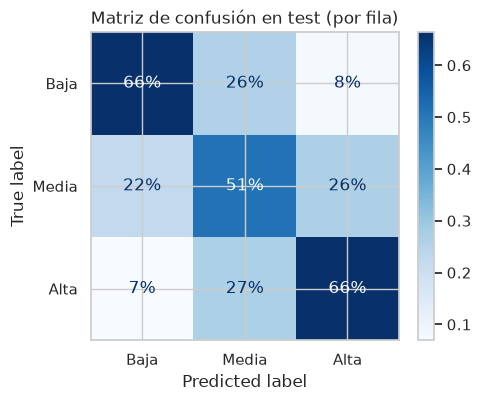

In [21]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test_clf, pred_clf, labels=clases, normalize="true",
                                        values_format=".0%", cmap="Blues", ax=ax)
ax.set_title("Matriz de confusión en test (por fila)")
plt.show()

La matriz se lee por fila: de cada clase real, qué porcentaje cayó en cada clase predicha. Los errores graves
(confundir Baja con Alta) son pocos, menos del 10 %. La mayor parte de los errores son con la clase vecina, y la
clase **Media** es la más difícil: está en el medio y se confunde con las dos.

## 12. Conclusiones

| | Regresión (`log1p(prod_pet)`) | Clasificación (Baja / Media / Alta) |
|---|---|---|
| Vara mínima (Dummy), validación | R² 0,00 | F1 macro 0,17 |
| Mejor modelo lineal, validación | R² 0,60 | F1 macro 0,59 |
| Random Forest por defecto, validación | R² 0,56 (entrenamiento 0,97) | F1 macro 0,56 (entrenamiento 0,97) |
| Random Forest optimizado, validación | R² 0,68 (entrenamiento 0,75) | F1 macro 0,60 (entrenamiento 0,66) |
| **Random Forest optimizado, test** | **R² 0,71 · MAE 0,65 (factor ≈ 1,9)** | **F1 macro 0,61 · accuracy 0,61 · AUC 0,80** |

**Qué respondimos.** Sí: con las características del pozo y los días que trabajó se explica cerca del 70 % de la
variación de la producción mensual de petróleo (en escala logarítmica). La predicción típica se equivoca por un
factor de 1,9: alcanza para ordenar pozos y separar los de baja productividad de los de alta, no para estimar
el volumen exacto de un pozo puntual.

**El sobreajuste fue el problema central.** El árbol sin límites y el Random Forest por defecto entrenan casi
perfecto y validan peor que una regresión lineal: memorizan los pozos que vieron. Optuna eligió hojas con al
menos 13 a 18 filas y árboles de profundidad 16 a 17, que achicaron la brecha entre entrenamiento y validación
(de 0,41 a 0,07 de R²) y mejoraron la validación. Por eso el Random Forest optimizado supera al lineal, que sin
optimizar no lo superaba.

**La validación fue honesta.** Separamos siempre por pozo (`GroupKFold`); el test se usó una
sola vez, y su resultado quedó en línea con la validación cruzada (incluso un poco mejor, porque el modelo final
se entrenó con todos los pozos y no con la muestra).

**Decisiones y límites.**
- Excluimos el gas, el agua y las variables derivadas del mismo mes para no filtrar la respuesta; con ellas el
  R² subiría, pero el modelo no serviría para anticipar.
- Comparamos y optimizamos sobre una muestra de pozos por el tiempo de cómputo; el modelo final usa todo el
  entrenamiento.
- Los datos son de un solo año (2025). El modelo no sabe la edad del pozo ni su historia de producción, que
  probablemente explican buena parte de lo que falta.
- La clasificación hereda los límites de la regresión: la clase Media es la más difícil, porque sus bordes son
  cortes arbitrarios de una variable continua.

**Siguiente paso (pre-entrega 4).** Agrupar los pozos según su perfil productivo con un modelo no supervisado.